### Binning (Discretization)

**Binning** is a feature transformation technique that divides a continuous numerical variable into a set of intervals (bins). Each original value is replaced by the bin to which it belongs.

For example, ages can be grouped into ranges such as 0–18, 19–35, 36–60, and 61+.

**Why use it ?**
- Reduce the effect of small variations in continuous values.
- Simplify a feature and make patterns easier to interpret.
- Help models capture non-linear relationships through ranges.
- Reduce the influence of extreme values in some cases.

Binning loses some information because different values in the same interval receive the same bin representation. Choose bin ranges and the number of bins carefully.

In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [3]:
df = pd.read_csv('Datasets/titanic.csv',usecols=['Age','Fare','Survived'])

In [4]:
df.shape

(891, 3)

In [5]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [6]:
df.dropna(inplace=True)

In [7]:
df.shape

(714, 3)

In [8]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [9]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [10]:
clf = DecisionTreeClassifier()
clf.fit(X_train,y_train)

DecisionTreeClassifier()

In [11]:
y_pred = clf.predict(X_test)
accuracy_score(y_test,y_pred)

0.6363636363636364

In [12]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6275234741784037)

#### `KBinsDiscretizer`

Scikit-learn's `KBinsDiscretizer` divides numerical features into a specified number of bins.

Important parameters:

- `n_bins`: number of intervals to create.
- `encode='ordinal'`: represents each bin with an integer such as `0, 1, 2, ...`.
- `strategy`: method used to determine the bin boundaries.

Common strategies:

| Strategy | How it creates bins | When useful |
|---|---|---|
| `uniform` | Equal-width intervals | When the numerical range itself is meaningful |
| `quantile` | Approximately equal number of samples per bin | When the feature is skewed or unevenly distributed |
| `kmeans` | Uses clustering to form bins | When values naturally form clusters |

With `encode='ordinal'`, the output is a bin index. The number is a label for the interval, not a measurement of distance between values.

In [13]:
kbin_age = KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')

In [14]:
trf = ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare,[1])
])

In [15]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

**Understanding bin edges and bin labels**

`bin_edges_` contains the learned boundaries of each bin. These boundaries are learned when the discretizer is fitted.

`pd.cut()` can use those boundaries to show the interval label for each original value. This makes it easier to compare a raw value with its assigned bin.

For example, an age of 27 might be assigned to an interval such as `(24.0, 31.0]`, depending on the learned boundaries.

In [17]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42,  6.  , 16.  , 19.  , 21.  , 23.  , 25.  , 28.  , 30.  ,
              32.  , 35.  , 38.  , 42.  , 47.  , 54.  , 80.  ])             ],
      dtype=object)

In [18]:
output = pd.DataFrame({
    'age':X_train['Age'],
    'age_trf':X_train_trf[:,0],
    'fare':X_train['Fare'],
    'fare_trf':X_train_trf[:,1]
})

In [19]:
output['age_labels'] = pd.cut(x=X_train['Age'],
                                    bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x=X_train['Fare'],
                                    bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [20]:
output.sample(10)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
57,28.5,7.0,7.2292,0.0,"(28.0, 30.0]","(0.0, 7.25]"
606,30.0,8.0,7.8958,3.0,"(28.0, 30.0]","(7.775, 7.896]"
33,66.0,14.0,10.5000,5.0,"(54.0, 80.0]","(8.158, 10.5]"
450,36.0,10.0,27.7500,10.0,"(35.0, 38.0]","(26.55, 31.275]"
370,25.0,6.0,55.4417,12.0,"(23.0, 25.0]","(51.479, 76.292]"
254,41.0,11.0,20.2125,8.0,"(38.0, 42.0]","(18.75, 26.0]"
117,29.0,7.0,21.0000,8.0,"(28.0, 30.0]","(18.75, 26.0]"
327,36.0,10.0,13.0000,6.0,"(35.0, 38.0]","(10.5, 13.0]"
554,22.0,4.0,7.7750,2.0,"(21.0, 23.0]","(7.25, 7.775]"
484,25.0,6.0,91.0792,13.0,"(23.0, 25.0]","(76.292, 108.9]"


In [21]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)

DecisionTreeClassifier()

In [22]:
y_pred2 = clf.predict(X_test_trf)
accuracy_score(y_test,y_pred2)

0.6363636363636364

In [23]:
X_trf = trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6289514866979656)

In [24]:
def discretize(bins, strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    
    trf = ColumnTransformer([
        ('first', kbin_age, [0]),
        ('second', kbin_fare, [1])
    ])
    
    X_trf = trf.fit_transform(X)
    # Note: Using X_trf here evaluates the discretized features (your original code passed X)
    print(np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy')))
    
    # --- Age Plots ---
    plt.figure(figsize=(14, 4))
    
    plt.subplot(121)
    plt.hist(X['Age'], bins=bins)
    plt.title("Age - Before Discretization")
    plt.xlabel("Age")
    plt.ylabel("Frequency")

    plt.subplot(122)
    plt.hist(X_trf[:, 0], bins=bins, color='red')
    plt.title(f"Age - After ({strategy}, {bins} bins)")
    plt.xlabel("Age Bin")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()
    
    # --- Fare Plots ---
    plt.figure(figsize=(14, 4))
    
    plt.subplot(121)
    plt.hist(X['Fare'], bins=bins)
    plt.title("Fare - Before Discretization")
    plt.xlabel("Fare")
    plt.ylabel("Frequency")

    plt.subplot(122)
    plt.hist(X_trf[:, 1], bins=bins, color='red')
    plt.title(f"Fare - After ({strategy}, {bins} bins)")
    plt.xlabel("Fare Bin")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

0.6556142410015648


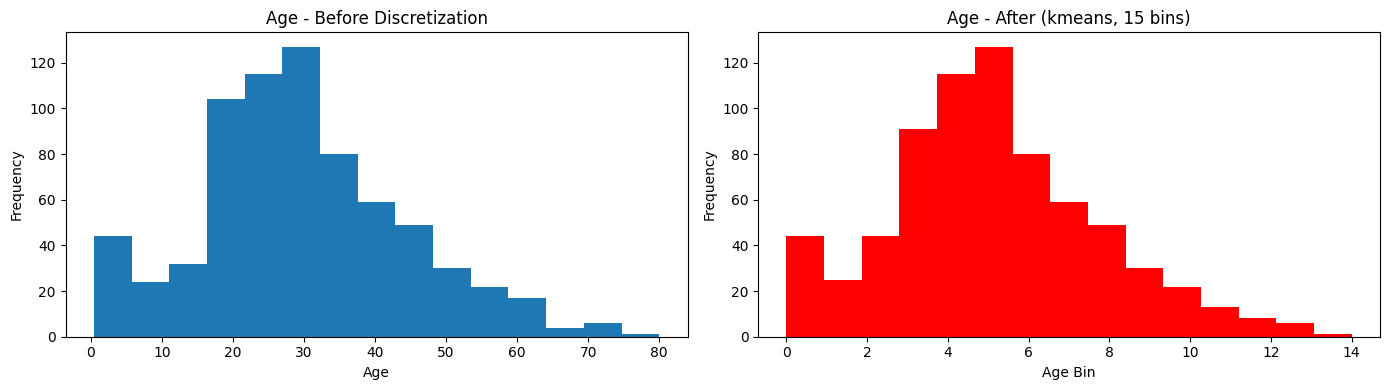

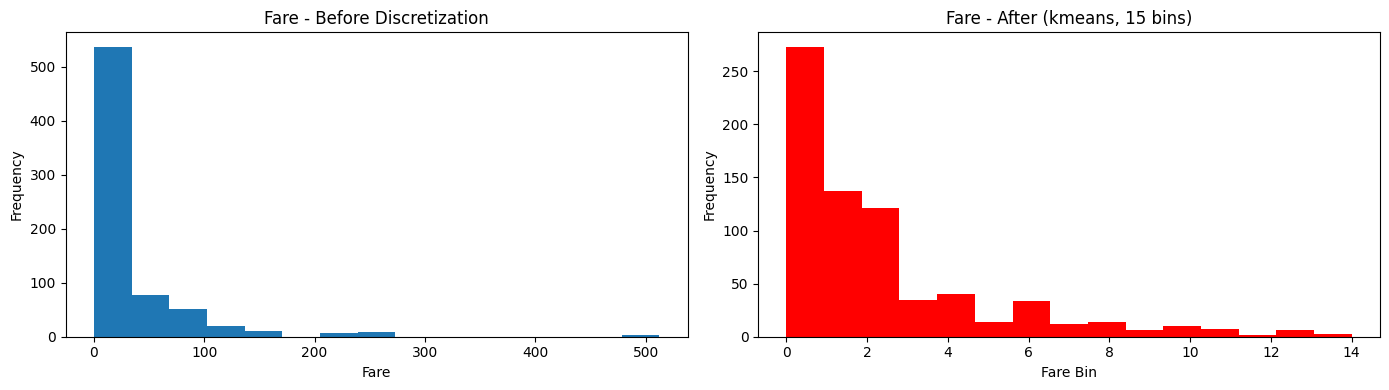

In [25]:
discretize(15,'kmeans')

0.682140062597809


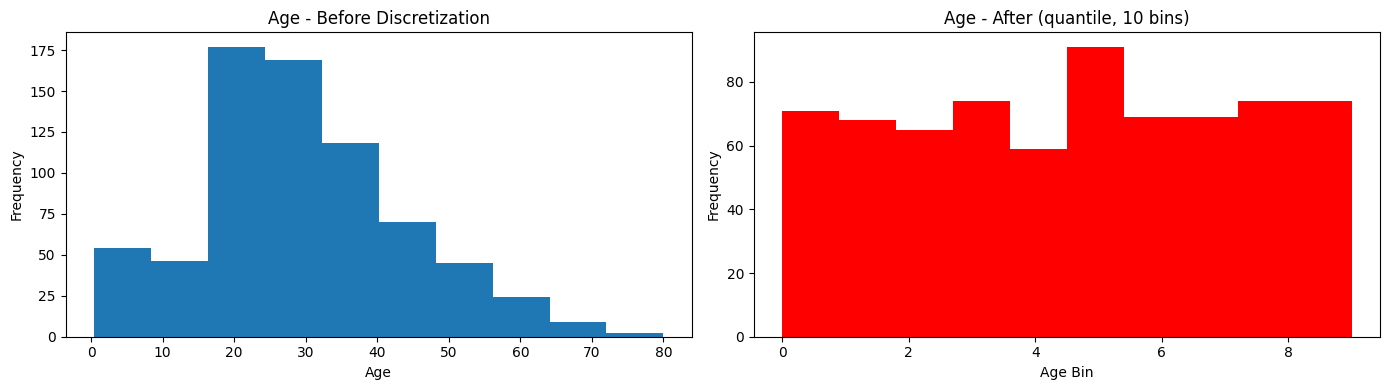

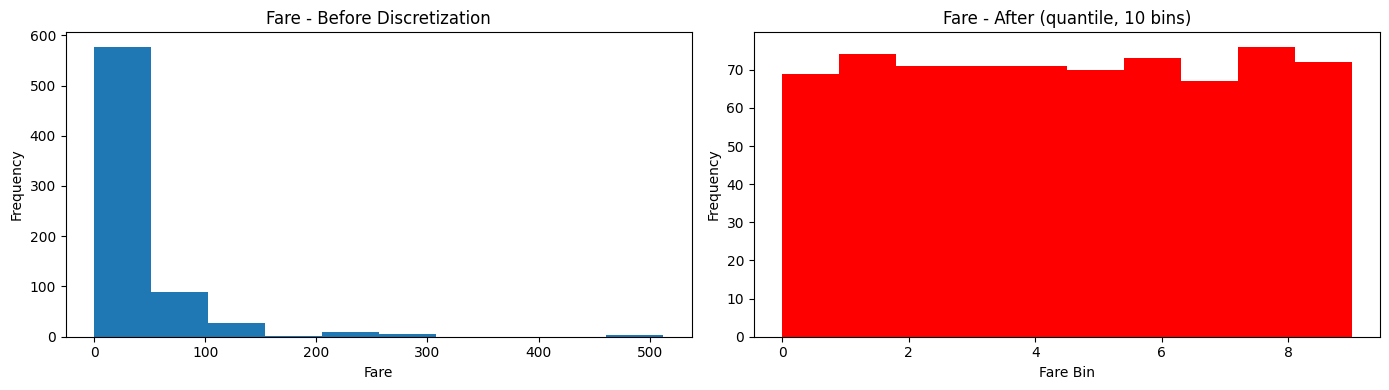

In [26]:
discretize(10,'quantile')

### Binarization

**Binarization** converts numerical values into binary values, usually `0` or `1`, by applying a threshold.

For example, with a threshold of 3:

- Values greater than 3 become `1`.
- Values less than or equal to 3 become `0`.

In this notebook, `family` is created by adding `SibSp` and `Parch`, then binarized to indicate whether a passenger travelled with family.

**Why use it ?**
- Convert a count or measurement into a yes/no indicator.
- Represent the presence or absence of a condition.
- Simplify a feature when the exact magnitude is less important than crossing a threshold.

Binarization discards magnitude information, so use it only when the binary distinction is meaningful.

In [27]:
df = pd.read_csv('Datasets/titanic.csv')[['Age','Fare','SibSp','Parch','Survived']]

In [28]:
df.dropna(inplace=True)

In [29]:
df.head()

,Age,Fare,SibSp,Parch,Survived
0,22.0,7.2500,1,0,0
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,1
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,0


In [30]:
df['family'] = df['SibSp'] + df['Parch']
df.head()

,Age,Fare,SibSp,Parch,Survived,family
0,22.0,7.2500,1,0,0,1
1,38.0,71.2833,1,0,1,1
2,26.0,7.9250,0,0,1,0
3,35.0,53.1000,1,0,1,1
4,35.0,8.0500,0,0,0,0


In [31]:
df.drop(columns=['SibSp','Parch'],inplace=True)
df.head()

,Age,Fare,Survived,family
0,22.0,7.2500,0,1
1,38.0,71.2833,1,1
2,26.0,7.9250,1,0
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [32]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [33]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

X_train.head()

,Age,Fare,family
328,31.0,20.5250,2
73,26.0,14.4542,1
253,30.0,16.1000,1
719,33.0,7.7750,0
666,25.0,13.0000,0


In [34]:
# Without binarization

clf = DecisionTreeClassifier()
clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)

print("Without binarization")
print("-"*50)
print("Accuaracy Score : ", accuracy_score(y_test,y_pred))
print("Cross Val Score : ", np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy')))

Without binarization
--------------------------------------------------
Accuaracy Score :  0.6223776223776224
Cross Val Score :  0.6527582159624413


**`Binarizer` in Scikit-learn**

`Binarizer` applies a threshold to numerical values.

- `threshold`: values greater than the threshold become `1`; values less than or equal to it become `0`.
- `copy=False`: allows the transformer to try to modify the input array instead of always making a copy.

The default threshold is `0.0`. Therefore, with the default setting, positive values become `1` and zero or negative values become `0`.

Here, the `family` feature is transformed while `remainder='passthrough'` keeps the other selected columns unchanged.

In [35]:
# Applying Binarization

from sklearn.preprocessing import Binarizer

trf = ColumnTransformer([
    ('bin',Binarizer(copy=False),['family'])
],remainder='passthrough')

X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

pd.DataFrame(X_train_trf,columns=['family','Age','Fare'])

,family,Age,Fare
0,1.0,31.0,20.5250
1,1.0,26.0,14.4542
2,1.0,30.0,16.1000
3,0.0,33.0,7.7750
4,0.0,25.0,13.0000
...,...,...,...
566,1.0,46.0,61.1750
567,0.0,25.0,13.0000
568,0.0,41.0,134.5000
569,1.0,33.0,20.5250


In [36]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)


print("After Appying Binarization")
print("-"*50)

print("Accuracy Score : ",accuracy_score(y_test,y_pred2))

X_trf = trf.fit_transform(X)
print("Cross Val Score : ", np.mean(cross_val_score(DecisionTreeClassifier(),X_trf,y,cv=10,scoring='accuracy')))

After Appying Binarization
--------------------------------------------------
Accuracy Score :  0.6153846153846154
Cross Val Score :  0.6248239436619718


#### Binning vs. Binarization

| Binning | Binarization |
|---|---|
| Divides a continuous feature into multiple intervals | Converts values into two groups, usually 0 and 1 |
| Produces multiple bins, e.g. 0, 1, 2, 3 | Produces only 0 or 1 |
| Useful for grouping ranges of values | Useful for presence/absence or threshold decisions |
| Example: age groups | Example: travelled with family or not |

#### When should you use each ?

- **Binning :** use when ranges or groups are meaningful, or when a model may benefit from a grouped representation of a continuous feature.
- **Binarization :** use when a threshold has a meaningful interpretation and the exact value beyond that threshold is not important.

#### Important considerations

- Both techniques lose information compared with the original numerical values.
- The number of bins, binning strategy, and binarization threshold should be chosen thoughtfully.
- Compare the transformed feature with the original using validation data.
- For cross-validation, place the discretizer or binarizer inside a `Pipeline` so learned preprocessing is applied separately within each training fold.

#### Key takeaway

**Binning creates multiple value ranges; binarization creates a two-way split.** Use them only when the simplified representation is useful for the problem.